In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/netflix_titles.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("netflix_titles.csv")

# Check original dataset
print("Original shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

# Make a copy for cleaning
clean_df = df.copy()

# Handle missing categorical values
categorical_cols = [
    "director", "cast", "country",
    "rating", "duration"
]

for col in categorical_cols:
    clean_df[col] = clean_df[col].fillna("Unknown")

# Convert date_added into datetime
clean_df["date_added"] = pd.to_datetime(
    clean_df["date_added"].str.strip(),
    errors="coerce"
)

# Extract duration numbers
clean_df["duration_value"] = pd.to_numeric(
    clean_df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Extract duration unit
clean_df["duration_unit"] = (
    clean_df["duration"].str.extract(r"([A-Za-z]+)")[0]
)

# Check cleaned dataset
print("\nCleaned shape:", clean_df.shape)
print("\nRemaining missing values:")
print(clean_df.isnull().sum())

# Save cleaned dataset
clean_df.to_csv("netflix_cleaned.csv", index=False)


Original shape: (8807, 12)

Missing values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Duplicate records: 0

Cleaned shape: (8807, 14)

Remaining missing values:
show_id            0
type               0
title              0
director           0
cast               0
country            0
date_added        10
release_year       0
rating             0
duration           0
listed_in          0
description        0
duration_value     3
duration_unit      0
dtype: int64


Netflix Content Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


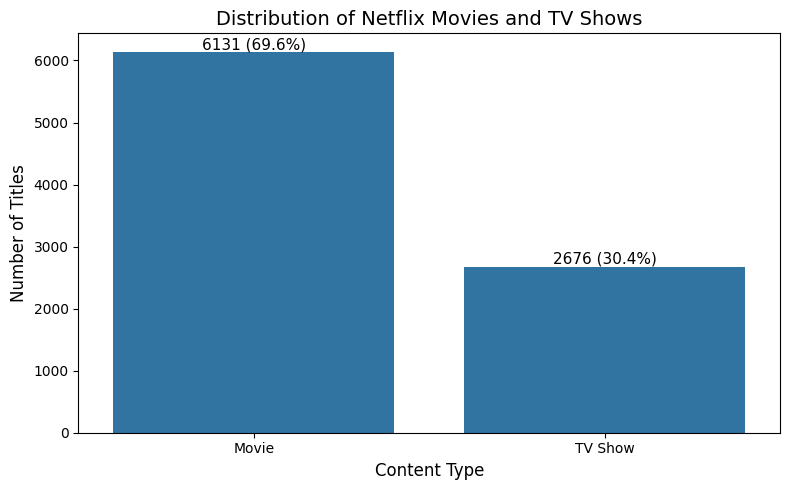


Graph 1 completed successfully!
Total titles: 8807
Movies: 6131
TV Shows: 2676


In [9]:

# GRAPH 1: Netflix Movies vs TV Shows

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Create plots folder
os.makedirs("plots", exist_ok=True)

# Step 2: Load dataset if not already loaded
if "clean_df" not in globals():
    clean_df = pd.read_csv("netflix_titles.csv")

# Step 3: Check content type
clean_df["type"] = clean_df["type"].astype(str).str.strip()

# Step 4: Count Movies and TV Shows
content_counts = clean_df["type"].value_counts()

print("Netflix Content Distribution:")
print(content_counts)

# Step 5: Calculate percentages
percentages = (
    content_counts / content_counts.sum() * 100
)

# Step 6: Create bar chart
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=clean_df,
    x="type",
    order=["Movie", "TV Show"]
)

# Add values and percentages above bars
for bar in ax.patches:
    height = bar.get_height()
    percentage = (height / content_counts.sum()) * 100

    ax.annotate(
        f'{int(height)} ({percentage:.1f}%)',
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=11
    )

# Step 7: Add titles and labels
plt.title(
    "Distribution of Netflix Movies and TV Shows",
    fontsize=14
)

plt.xlabel("Content Type", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.tight_layout()

# Step 8: Save graph
plt.savefig(
    "plots/graph1_content_type.png",
    dpi=300,
    bbox_inches="tight"
)

# Step 9: Display graph
plt.show()

# Step 10: Print results
print("\nGraph 1 completed successfully!")
print("Total titles:", content_counts.sum())
print("Movies:", content_counts.get("Movie", 0))
print("TV Shows:", content_counts.get("TV Show", 0))


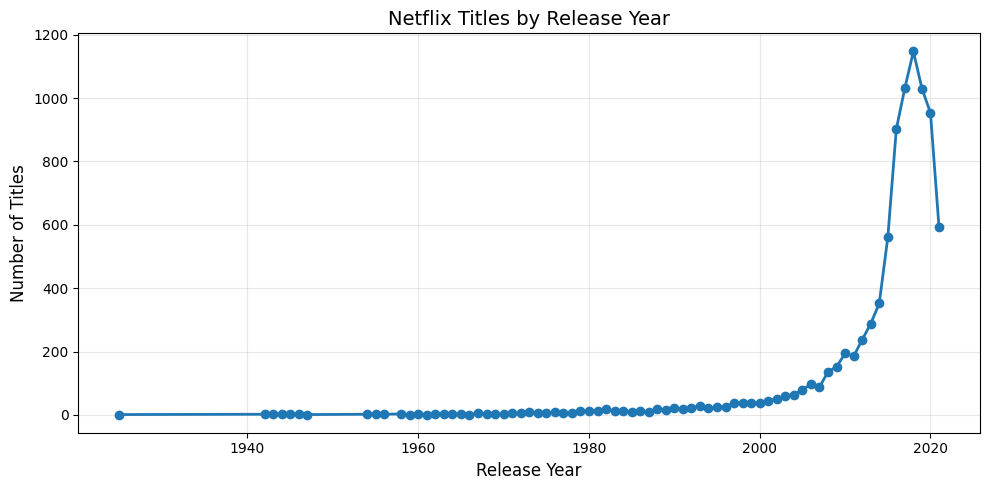

Graph 2 completed successfully!
Highest release year: 2018
Highest number of titles: 1147


In [7]:

# GRAPH 2: Netflix Titles by Release Year

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create plots folder automatically
os.makedirs("plots", exist_ok=True)

# Check dataset
if "clean_df" not in globals():
    clean_df = pd.read_csv("netflix_titles.csv")

# Convert release_year to numeric
clean_df["release_year"] = pd.to_numeric(
    clean_df["release_year"], errors="coerce"
)

# Remove missing and invalid years
year_data = clean_df.dropna(subset=["release_year"]).copy()

# Count titles by release year
year_counts = (
    year_data.groupby("release_year")
    .size()
    .sort_index()
)

# Create line graph
plt.figure(figsize=(10, 5))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker="o",
    linewidth=2
)

plt.title("Netflix Titles by Release Year", fontsize=14)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig(
    "plots/graph2_release_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display statistical information
print("Graph 2 completed successfully!")
print("Highest release year:", year_counts.idxmax())
print("Highest number of titles:", year_counts.max())


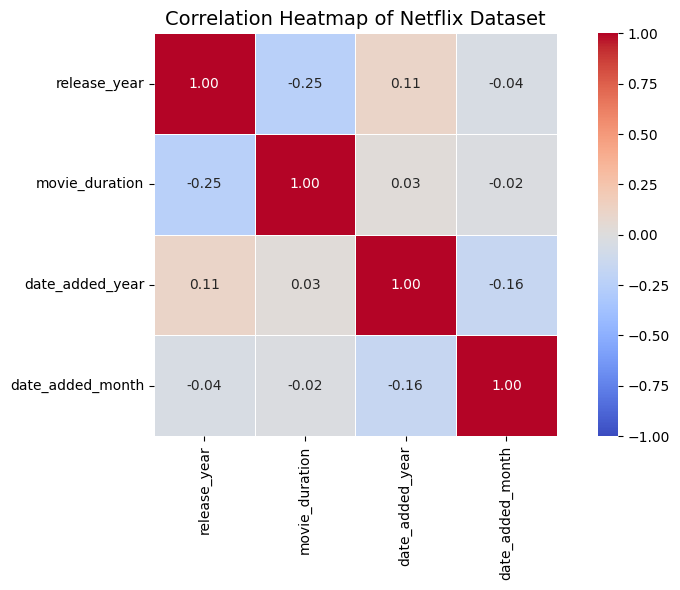

Graph 3 Heatmap created successfully!

Correlation values:
                  release_year  movie_duration  date_added_year  \
release_year          1.000000       -0.249182         0.111531   
movie_duration       -0.249182        1.000000         0.029345   
date_added_year       0.111531        0.029345         1.000000   
date_added_month     -0.039179       -0.017311        -0.160421   

                  date_added_month  
release_year             -0.039179  
movie_duration           -0.017311  
date_added_year          -0.160421  
date_added_month          1.000000  


In [10]:

# GRAPH 3: Netflix Correlation Heatmap

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Create plots folder
os.makedirs("plots", exist_ok=True)

# Step 2: Load dataset if not already loaded
if "clean_df" not in globals():
    clean_df = pd.read_csv("netflix_titles.csv")

# Step 3: Create a separate analysis dataframe
heatmap_df = clean_df.copy()

# Step 4: Convert release year to numeric
heatmap_df["release_year"] = pd.to_numeric(
    heatmap_df["release_year"], errors="coerce"
)

# Step 5: Extract movie duration in minutes
heatmap_df["movie_duration"] = pd.to_numeric(
    heatmap_df["duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Step 6: Convert date_added into datetime
heatmap_df["date_added"] = pd.to_datetime(
    heatmap_df["date_added"].astype(str).str.strip(),
    errors="coerce"
)

# Step 7: Extract date added year and month
heatmap_df["date_added_year"] = (
    heatmap_df["date_added"].dt.year
)

heatmap_df["date_added_month"] = (
    heatmap_df["date_added"].dt.month
)

# Step 8: Select numerical columns
numeric_data = heatmap_df[
    [
        "release_year",
        "movie_duration",
        "date_added_year",
        "date_added_month"
    ]
].copy()

# Step 9: Calculate correlation
correlation = numeric_data.corr(method="pearson")

# Step 10: Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Correlation Heatmap of Netflix Dataset",
    fontsize=14
)

plt.tight_layout()

# Step 11: Save heatmap
plt.savefig(
    "plots/graph3_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

# Step 12: Display heatmap
plt.show()

print("Graph 3 Heatmap created successfully!")
print("\nCorrelation values:")
print(correlation)
